# Late Deliveries: analysis

This notebook shows the results of `python -m latedeliveries.train`. It reads the saved
model and reports instead of retraining, so **the test set is not scored again here**:
the test numbers come from `reports/metrics.json`, written once by `train.py`.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from latedeliveries.data import make_orders
from latedeliveries.evaluation import cost_by_threshold
from latedeliveries.pipeline import CATEGORICAL, NUMERIC, SEED, TARGET, load_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
X, y, X_train, X_test, y_train, y_test = load_split()
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
BLUE, GREY = "#2a78d6", "#52514e"

## 1. How common are late orders?

About one order in six is late, so a model that always says "on time" is already right
84% of the time. Accuracy alone cannot judge this problem.

In [2]:
print(f"Late orders: {y.sum()} of {len(y)} ({y.mean():.1%})")
print(f"Train late rate {y_train.mean():.3f}, test late rate {y_test.mean():.3f}")
y.value_counts().rename(index={0: "on time", 1: "late"})

Late orders: 468 of 3000 (15.6%)
Train late rate 0.156, test late rate 0.156


late
on time    2532
late        468
Name: count, dtype: int64

## 2. Model comparison (5-fold CV, training data only)

Mean and standard deviation over five folds, from `reports/cv_results.csv`.

In [3]:
pd.read_csv(ROOT / "reports" / "cv_results.csv").set_index("model")

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
model,,,,,,,,,,
baseline,0.844,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000
logistic,0.868,0.011,0.688,0.089,0.273,0.048,0.391,0.062,0.812,0.034
logistic_balanced,0.745,0.013,0.345,0.019,0.704,0.038,0.463,0.024,0.811,0.034
random_forest,0.858,0.007,0.731,0.105,0.137,0.036,0.229,0.055,0.794,0.031
gradient_boosting,0.862,0.008,0.627,0.063,0.279,0.053,0.384,0.059,0.789,0.032


## 3. Cost against threshold

Out-of-fold probabilities on the training data, from the saved model's settings.
Cost = $4 for every order flagged + $15 for every late order not flagged.

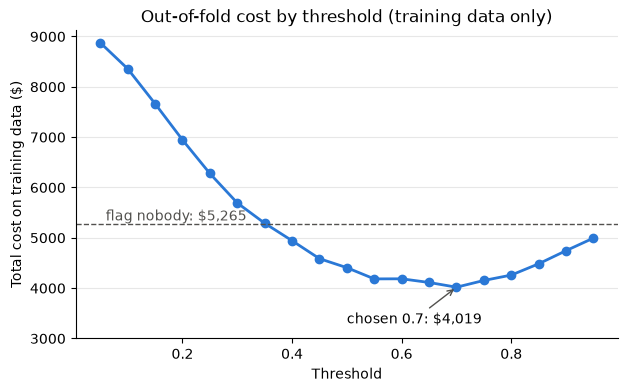

In [4]:
info = json.loads((ROOT / "models" / "model_info.json").read_text())
model = joblib.load(ROOT / "models" / "late_orders.joblib")
probability = cross_val_predict(
    clone(model), X_train, y_train, cv=folds, method="predict_proba"
)[:, 1]
costs = cost_by_threshold(y_train, probability)
nobody = 15 * int(y_train.sum())
threshold = info["threshold"]
best_cost = costs.set_index("threshold").loc[threshold, "cost"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(costs["threshold"], costs["cost"], color=BLUE, linewidth=2, marker="o")
ax.axhline(nobody, color=GREY, linewidth=1, linestyle="--")
ax.text(0.06, nobody + 80, f"flag nobody: ${nobody:,}", color=GREY)
ax.annotate(
    f"chosen {threshold}: ${best_cost:,}",
    (threshold, best_cost),
    xytext=(0.5, 3300),
    arrowprops={"arrowstyle": "->", "color": GREY},
)
ax.set_ylim(3000, None)
ax.set(
    xlabel="Threshold",
    ylabel="Total cost on training data ($)",
    title="Out-of-fold cost by threshold (training data only)",
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

## 4. Test set, used once

The confusion matrix and metrics at the chosen threshold, from `reports/metrics.json`.

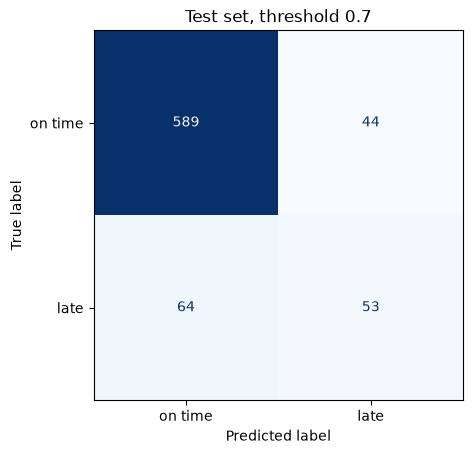

{'precision': 0.546, 'recall': 0.453, 'f1': 0.495, 'roc_auc': 0.821}

In [5]:
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
ConfusionMatrixDisplay(
    np.array(metrics["confusion_matrix"]), display_labels=["on time", "late"]
).plot(cmap="Blues", colorbar=False)
plt.title(f"Test set, threshold {metrics['threshold']}")
plt.show()
{k: metrics[k] for k in ["precision", "recall", "f1", "roc_auc"]}

## 5. Cost of three policies on the test set

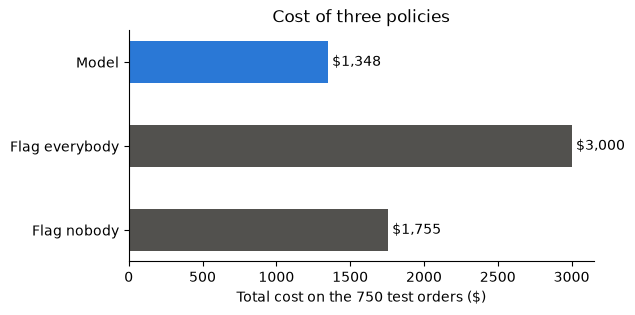

Saving against flagging nobody: $407 (23%)


In [6]:
policy = pd.Series(metrics["cost"]).rename(
    {"flag_nobody": "Flag nobody", "flag_everybody": "Flag everybody", "model": "Model"}
)
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(policy.index, policy.values, color=[GREY, GREY, BLUE], height=0.5)
for i, value in enumerate(policy.values):
    ax.text(value + 30, i, f"${value:,}", va="center")
ax.set(xlabel="Total cost on the 750 test orders ($)", title="Cost of three policies")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
saving = metrics["cost"]["flag_nobody"] - metrics["cost"]["model"]
print(
    f"Saving against flagging nobody: ${saving} ({saving / policy['Flag nobody']:.0%})"
)

## 6. Leakage check

The same model, cross-validated on the training rows, with and without
`customer_rating`. This is a check only: the saved model never sees that column.

In [7]:
def leak_check(numeric):
    """CV ROC-AUC of the chosen model on the training rows, with these numbers."""
    orders = make_orders().loc[X_train.index]
    prep = ColumnTransformer(
        [
            (
                "num",
                make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                numeric,
            ),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
        ]
    )
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    pipe = Pipeline([("prep", prep), ("model", model)])
    scores = cross_val_score(pipe, orders, orders[TARGET], cv=folds, scoring="roc_auc")
    return f"{scores.mean():.3f} +/- {scores.std():.3f}"


print("Without customer_rating:", leak_check(NUMERIC))
print("With customer_rating:   ", leak_check(NUMERIC + ["customer_rating"]))

Without customer_rating: 0.811 +/- 0.034
With customer_rating:    0.915 +/- 0.013


## Recommendation

**Would I use this model?** Yes, for the voucher decision. On 750 unseen test orders it
cost $1,348, against $1,755 for flagging nobody: a saving of $407 (23%), close to the
24% seen out-of-fold on the training data.

**Why this threshold?** 0.70 gave the lowest out-of-fold cost on the training data, and
the test set played no part in choosing it. It looks high because
`class_weight="balanced"` pushes the predicted probabilities up, so 0.70 here is not a
70% chance of being late.

**What did I exclude and why?** `customer_rating` is given after delivery and is made
from `late` itself, so it does not exist when an order is placed. Adding it back raises
CV ROC-AUC from 0.811 to 0.915: a leak, not skill. `order_id` is only a label.

**One limitation.** The data is invented, and the test set holds only 117 late orders,
so the $407 saving could easily move by a hundred dollars or more on another sample.
`prep_minutes` is assumed to be the restaurant's estimate, which in practice would be
noisier than the recorded value.